In [64]:
# Reading list

import pandas as pd

Guns = pd.read_csv("Gun_Seizures.csv")

Guns.head(10)

,_id,address,total_count,other_count,pistol_count,revolver_count,rifle_count,shotgun_count,year,month,dow,neighborhood,council_district,ward,tract,public_works_division,police_zone,fire_zone,latitude,longitude
0,1,"1700 BLOCK ARLINGTON AVE PITTSBURGH, PA 15210",2,0,1,1,0,0,2015,1,0,Mount Oliver Borough,3.0,0.0,4.200317e+10,0.0,3,4-6,40.417619,-79.986436
1,2,"BREVET WAY & MINTON ST PITTSBURGH, PA 15204",1,0,1,0,0,0,2015,1,0,Sheraden,2.0,20.0,4.200356e+10,5.0,6,1-16,40.456904,-80.052328
2,3,"TERRACE ST & WHITRIDGE ST PITTSBURGH, PA 15213",1,0,1,0,0,0,2015,1,0,Terrace Village,6.0,4.0,4.200305e+10,3.0,2,2-10,40.441185,-79.968527
3,4,"3500 BLOCK GERBER AVE PITTSBURGH, PA 15212",1,0,1,0,0,0,2015,1,0,Brighton Heights,1.0,27.0,4.200327e+10,1.0,1,1-14,40.479530,-80.033477
4,5,"7500 BLOCK KELLY ST PITTSBURGH, PA 15208",1,0,1,0,0,0,2015,1,0,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN
5,6,"1900 BLOCK 5TH AVE PITTSBURGH, PA 15219",1,0,1,0,0,0,2015,1,0,Westwood,2.0,28.0,4.200356e+10,5.0,6,1-18,40.435984,-80.052042
6,7,"400 BLOCK S NEGLEY AVE PITTSBURGH, PA 15232",1,0,1,0,0,0,2015,1,1,East Liberty,9.0,11.0,4.200311e+10,2.0,5,3-8,40.466771,-79.928240
7,8,"5200 BLOCK DRESDEN WAY PITTSBURGH, PA 15201",2,0,2,0,0,0,2015,1,1,Upper Lawrenceville,7.0,10.0,4.200310e+10,2.0,2,3-5,40.480147,-79.954014
8,9,"1100 BLOCK GRAND AVE PITTSBURGH, PA 15212",1,0,1,0,0,0,2015,1,1,Marshall-Shadeland,1.0,27.0,4.200327e+10,1.0,1,1-14,40.474986,-80.027528
9,10,"1600 BLOCK FALLOWFIELD AVE PITTSBURGH, PA 15216",1,0,1,0,0,0,2015,1,1,Beechview,4.0,19.0,4.200319e+10,5.0,6,4-28,40.410487,-80.023969


In [109]:
# Neigborhoods by total seizures

Tot_Guns = Guns.groupby("neighborhood")["total_count"].sum()
Guns_Sorted = Tot_Guns.reset_index().sort_values("total_count", ascending=False) 

Guns_Sorted.head(20)

,neighborhood,total_count
40,Homewood South,345
69,South Side Flats,208
39,Homewood North,159
12,Brighton Heights,149
27,East Liberty,148
15,Carrick,148
48,Marshall-Shadeland,148
37,Hazelwood,144
26,East Hills,137
60,Perry South,136


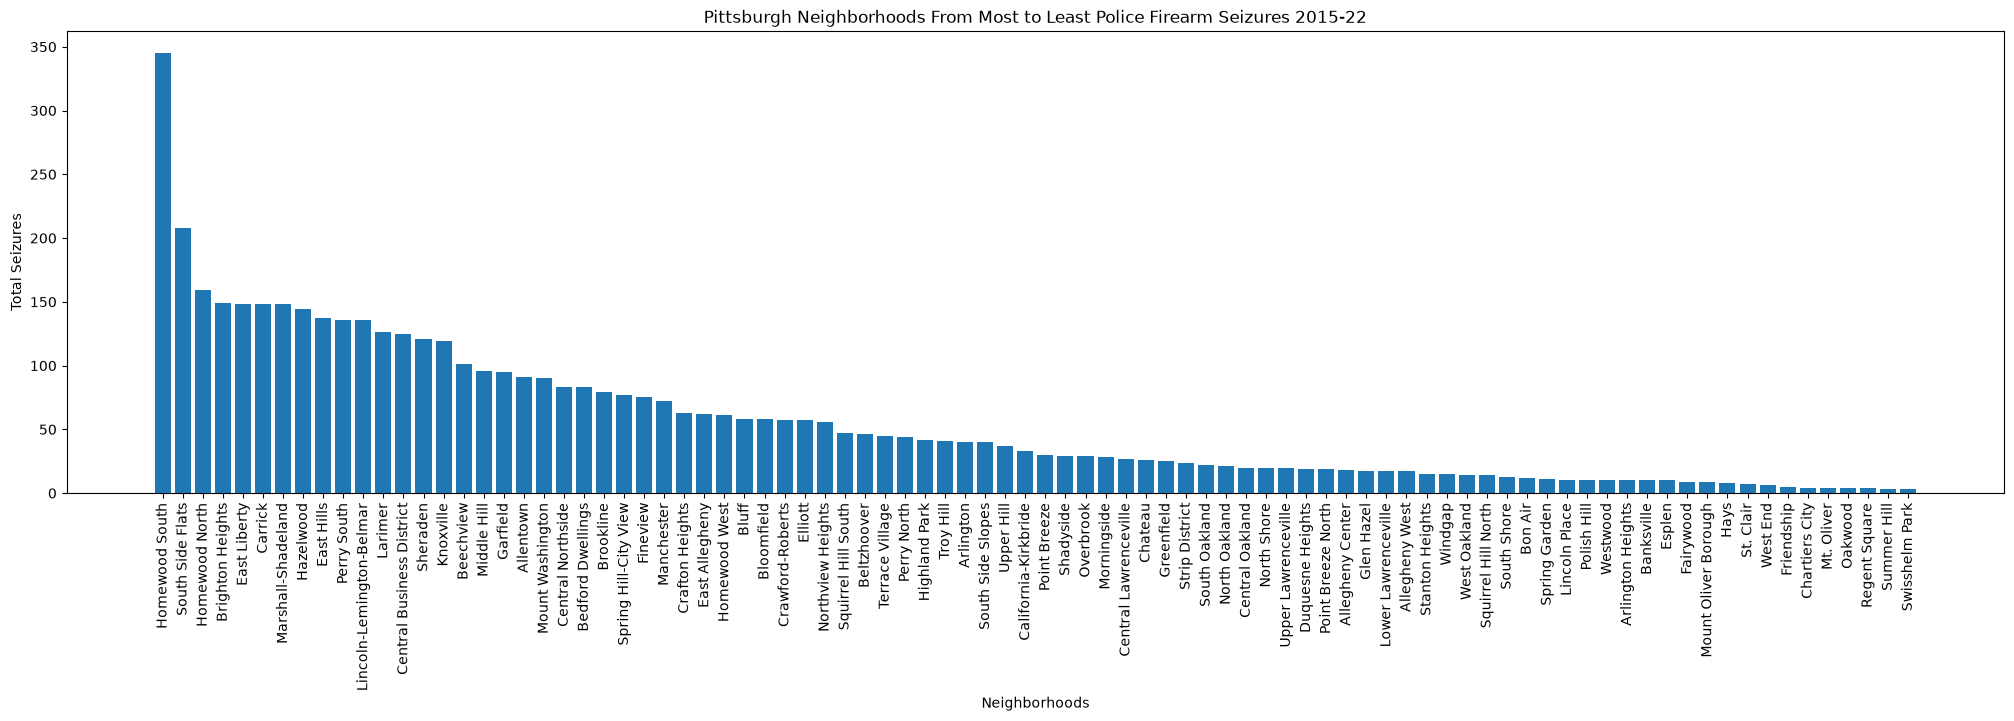

In [110]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 6))

plt.bar(Guns_Sorted["neighborhood"], Guns_Sorted["total_count"])
plt.xticks(rotation="vertical") # turn labels so they don't overlap

plt.xlabel("Neighborhoods")
plt.ylabel("Total Seizures")
plt.title("Pittsburgh Neighborhoods From Most to Least Police Firearm Seizures 2015-22")

plt.show()

In [108]:
# Neigborhoods by Rifle/ shotgun seizures

Rifles = Guns.groupby("neighborhood")["rifle_count"].sum()
Shotguns = Guns.groupby("neighborhood")["shotgun_count"].sum()
Total = pd.DataFrame({"neighborhood": Guns["neighborhood"], "total_large_guns": Guns["rifle_count"] + Guns["shotgun_count"]}).groupby("neighborhood").sum()

Large_Arms = pd.merge(Total, Rifles, how = 'outer', on = "neighborhood")
Large_Arms = pd.merge(Large_Arms, Shotguns, how = 'outer', on = "neighborhood")

Large_Arms_Sorted = Large_Arms.reset_index().sort_values("total_large_guns", ascending=False) 

Large_Arms_Sorted.head(20)

,neighborhood,total_large_guns,rifle_count,shotgun_count
40,Homewood South,40,25,15
27,East Liberty,38,29,9
12,Brighton Heights,31,24,7
15,Carrick,31,21,10
48,Marshall-Shadeland,26,13,13
37,Hazelwood,23,16,7
42,Knoxville,19,11,8
7,Beechview,19,7,12
13,Brookline,17,12,5
39,Homewood North,16,13,3


In [107]:
# Neigborhoods by revolver seizures

Revolvers = Guns.groupby("neighborhood")["revolver_count"].sum()
Handguns = Guns.groupby("neighborhood")["pistol_count"].sum()
Total = pd.DataFrame({"neighborhood": Guns["neighborhood"], "total_handguns": Guns["pistol_count"] + Guns["revolver_count"]}).groupby("neighborhood").sum()

Small_Arms = pd.merge(Total, Revolvers, how = 'outer', on = "neighborhood")
Small_Arms = pd.merge(Small_Arms, Handguns, how = 'outer', on = "neighborhood")

Small_Arms_Sorted = Small_Arms.reset_index().sort_values("total_handguns", ascending=False) 

Small_Arms_Sorted.head(20)

,neighborhood,total_handguns,revolver_count,pistol_count
40,Homewood South,300,43,257
69,South Side Flats,199,12,187
39,Homewood North,141,20,121
26,East Hills,128,19,109
16,Central Business District,122,15,107
43,Larimer,122,19,103
60,Perry South,120,15,105
48,Marshall-Shadeland,119,10,109
45,Lincoln-Lemington-Belmar,119,21,98
37,Hazelwood,119,14,105
